# 01 · 数据质量检查与探索性分析（EDA）

**项目背景**：一家电商公司设计了新版落地页（`new_page`），想知道它能否比旧版（`old_page`）带来更高的**转化率**（用户是否完成购买）。公司把访客随机分成两组：

| 组别 | 应看到的页面 | 角色 |
|---|---|---|
| `control` 对照组 | `old_page` | 基准 |
| `treatment` 实验组 | `new_page` | 待验证的改动 |

**本 notebook 的学习目标**
1. 在做任何统计检验之前，先确认数据"可信"：分组是否正确、用户是否重复、分流比例是否正常（SRM）。
2. 观察流量与转化率随时间的变化，判断实验期间是否有异常。
3. 检查两组在用户特征（国家）上是否平衡，以确认随机化有效。

> 💡 **面试要点**：资深分析师常说"A/B 测试 80% 的坑在数据质量"。先查数据、再看结果，是最能体现专业度的习惯。

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, str(Path("..", "src").resolve()))
from abtest import load_raw, clean_ab_data, srm_check
from abtest.plotting import set_style, GROUP_COLORS, MUTED

set_style()
FIG = Path("..", "reports", "figures")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.4f}".format)

ab_raw, countries = load_raw()
ab_raw.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


## 1. 认识数据

| 字段 | 含义 |
|---|---|
| `user_id` | 用户 ID —— **随机化单位**（每个用户被分到一个组） |
| `timestamp` | 用户进入实验的时间 |
| `group` | 被分配的组别 |
| `landing_page` | 实际看到的页面 |
| `converted` | 是否转化（1 = 购买，0 = 未购买）—— **核心指标** |

`countries.csv` 提供每个用户的国家，用于后面的分群分析。

In [2]:
print(f"行数: {len(ab_raw):,}   唯一用户数: {ab_raw.user_id.nunique():,}")
print(f"时间范围: {ab_raw.timestamp.min()}  →  {ab_raw.timestamp.max()}")
print(f"缺失值:\n{ab_raw.isna().sum()}")
print(f"整体转化率: {ab_raw.converted.mean():.4f}")

行数: 294,478   唯一用户数: 290,584
时间范围: 2017-01-02 13:42:05.378582  →  2017-01-24 13:41:54.460509
缺失值:
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64
整体转化率: 0.1197


**观察**：行数（294,478）比唯一用户数（290,584）多出 3,894 行，说明有用户出现了不止一次。没有缺失值。实验持续约 22 天。

## 2. 数据质量问题一：分组与页面不匹配

按设计，`control` 只能看到 `old_page`，`treatment` 只能看到 `new_page`。用交叉表检查：

In [3]:
pd.crosstab(ab_raw["group"], ab_raw["landing_page"], margins=True)

landing_page,new_page,old_page,All
group,,,
control,1928,145274,147202
treatment,145311,1965,147276
All,147239,147239,294478


有 1,928 + 1,965 = **3,893 行**的"组别"和"页面"不一致。

再往下查一步会发现：**这 3,893 行全部属于"出现两次"的用户**。每个这样的用户恰好有 2 行，一行组别和页面一致，另一行不一致（见下方代码）。也就是说，这些用户并不是"只看错了页面"，而是**进入实验两次、很可能两个页面都看过**（被"污染"的用户）。

**为什么要删除错配行？**
- 错配行的处理和分组标签矛盾，我们无法判断这一行的转化反映的是哪个页面的效果。
- 现实中这通常是**埋点 bug 或分流系统 bug**（例如同一用户被重复分流）。涉及约 1.3% 的用户，且两组数量接近（不像是某一组系统性出错）。
- 本项目沿用 Udacity 课题的常用规则：**删除错配行、保留这些用户一致的那一行**。这是一个判断，不是唯一正确的做法：大约一半的污染用户，错配行反而是他们的**第一次**曝光。第 3 节末尾的**敏感性分析**比较了几种规则，结论都不变。

**面试时的严谨说法**：删除前应确认这些"错配"在两组之间是对称的；如果它只发生在实验组（例如新页面加载失败跳回旧页面），直接删除会造成**选择偏差**，这时更好的做法是按"意向处理（Intention-to-Treat, ITT）"原则保留原分组分析。

In [4]:
mis = ab_raw[~(((ab_raw.group == "control") & (ab_raw.landing_page == "old_page")) |
                ((ab_raw.group == "treatment") & (ab_raw.landing_page == "new_page")))]
rows_per_user = ab_raw.groupby("user_id").size()
print(f"错配行: {len(mis):,}，涉及用户: {mis.user_id.nunique():,}")
print(f"这些用户在原始数据中的行数分布: {rows_per_user[mis.user_id.unique()].value_counts().to_dict()}")
first = ab_raw.sort_values("timestamp").drop_duplicates("user_id")
print(f"其中错配行是首次曝光的用户: {first.index.isin(mis.index).sum():,}")

错配行: 3,893，涉及用户: 3,893
这些用户在原始数据中的行数分布: {2: 3893}


其中错配行是首次曝光的用户: 1,949


## 3. 数据质量问题二：重复用户

随机化单位是用户，统计检验假设**每个观测相互独立**。同一用户出现两次会违反独立性。

In [5]:
aligned = ((ab_raw.group == "control") & (ab_raw.landing_page == "old_page")) | \
          ((ab_raw.group == "treatment") & (ab_raw.landing_page == "new_page"))
tmp = ab_raw[aligned]
dup_ids = tmp.loc[tmp.user_id.duplicated(), "user_id"]
tmp[tmp.user_id.isin(dup_ids)]

,user_id,timestamp,group,landing_page,converted
1899,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


删除错配后只剩 1 个重复用户（773192），我们保留其**第一次**进入实验的记录（第一次曝光才是"被分配"的时刻）。

> 注意：原始数据有 3,894 个用户出现两次。其中 3,893 个已经在删除错配行时变成一行，只有 773192 的两行都是一致的。所以清洗后的 290,584 行正好等于原始的唯一用户数：**我们没有删掉任何用户，只删掉了多余的行**。

下面用封装好的 `clean_ab_data()` 一次性完成清洗，后续 notebook 都调用同一个函数，保证口径一致。

In [6]:
df = clean_ab_data(ab_raw, countries)
df.head()

                      raw_rows: 294,478
       mismatched_rows_removed: 3,893
   duplicate_user_rows_removed: 1
               missing_country: 0
                    clean_rows: 290,584


,user_id,timestamp,group,landing_page,converted,country,date,treatment
0,922696,2017-01-02 13:42:05.378582,treatment,new_page,0,US,2017-01-02,1
1,781507,2017-01-02 13:42:15.234051,control,old_page,0,UK,2017-01-02,0
2,737319,2017-01-02 13:42:21.786186,control,old_page,0,US,2017-01-02,0
3,818377,2017-01-02 13:42:26.640581,treatment,new_page,0,US,2017-01-02,1
4,725857,2017-01-02 13:42:27.851110,treatment,new_page,0,US,2017-01-02,1


### 敏感性分析：换一种清洗规则，结论会变吗？

清洗规则是分析者的判断，好的做法是检查结论对它是否敏感。这里比较四种处理"出现两次"用户的方法（主分析在 02 中完成，这里只是提前确认）：

| 规则 | 做法 |
|---|---|
| A. 主分析（本项目） | 删除错配行，再按首次曝光去重 |
| B. 删除污染用户 | 只要用户有错配行，就整个删除该用户 |
| C. 意向处理（ITT） | 每个用户保留第一行，按**分组标签**归组 |
| D. 按实际页面 | 每个用户保留第一行，按**实际看到的页面**归组 |

In [7]:
from abtest import two_proportion_ztest

def summarize(d, label_col="group"):
    g = d.groupby(label_col).converted.agg(["sum", "count"])
    r = two_proportion_ztest(*g.iloc[0], *g.iloc[1])
    return {"用户数": len(d), "差值(pp)": r.abs_diff * 100,
            "CI 下限(pp)": r.ci_abs[0] * 100, "CI 上限(pp)": r.ci_abs[1] * 100, "p 值": r.p_value}

first_row = ab_raw.sort_values("timestamp").drop_duplicates("user_id").copy()
first_row["page_group"] = first_row.landing_page.map({"old_page": "control", "new_page": "treatment"})
contaminated = mis.user_id.unique()
pd.DataFrame({
    "A. 主分析": summarize(df),
    "B. 删除污染用户": summarize(df[~df.user_id.isin(contaminated)]),
    "C. ITT（首行，按分组）": summarize(first_row),
    "D. 首行，按实际页面": summarize(first_row, "page_group"),
}).T.astype({"用户数": int})

,用户数,差值(pp),CI 下限(pp),CI 上限(pp),p 值
A. 主分析,290584,-0.1578,-0.3938,0.0781,0.1899
B. 删除污染用户,286691,-0.1448,-0.3822,0.0926,0.2320
C. ITT（首行，按分组）,290584,-0.1587,-0.3946,0.0773,0.1876
D. 首行，按实际页面,290584,-0.1781,-0.4141,0.0579,0.1391


**解读**：四种规则下差值都在 −0.15 到 −0.18 个百分点之间，p 值都在 0.14–0.23 之间，置信区间都包含 0。**结论对清洗规则不敏感**，所以主分析沿用规则 A。

> 💡 **面试要点**：主动说"我检查了结论对清洗规则的敏感性"，比只说"我删掉了错配行"更能体现严谨性。

## 4. 样本比例失衡检验（SRM, Sample Ratio Mismatch）

### 概念
实验设计为 50/50 分流，那么两组人数应该很接近。如果实际比例明显偏离设计比例，就叫 **SRM**。SRM 是一个**数据质量警报**：它说明分流、埋点或数据管道出了问题，此时任何效果估计都**不可信**。

### 方法：卡方拟合优度检验
$$\chi^2 = \sum_{i} \frac{(O_i - E_i)^2}{E_i}, \qquad E_i = N \times \text{设计比例}_i$$

- $H_0$：实际分流比例 = 设计比例（50/50）
- 自由度 = 组数 − 1 = 1

### 为什么阈值用 0.001 而不是 0.05？
样本很大时，SRM 检验非常敏感；而且我们每个实验都会做 SRM 检查，用 0.05 会产生大量误报。业界（如微软 ExP 团队）普遍用 **p < 0.001** 作为警报线。

### SRM 的常见原因
重定向导致一组用户流失、机器人流量、某组页面加载更慢导致埋点丢失、实验中途调整了分流比例等。

In [8]:
counts = df.group.value_counts().reindex(["control", "treatment"])
srm = srm_check(counts.values)
print(f"观测人数: {srm.observed}")
print(f"期望人数: {srm.expected}")
print(f"chi2 = {srm.chi2:.4f},  p = {srm.p_value:.4f},  SRM? {srm.srm_detected}")

观测人数: (145274, 145310)
期望人数: (145292.0, 145292.0)
chi2 = 0.0045,  p = 0.9468,  SRM? False


**解读**：p ≈ 0.95，远大于 0.001，两组人数差异（36 人）完全可以用随机波动解释，**没有 SRM**，可以继续分析。

> ⚠️ 注意：SRM 检验应在**清洗后的分析样本**上做，因为它检查的是"进入分析的样本"是否被系统性扭曲。如果在清洗前做也正常、清洗后却失衡，说明清洗规则本身引入了偏差。

In [9]:
# 也检查清洗前（只看 group 标签）的分流
srm_raw = srm_check(ab_raw.group.value_counts().reindex(["control", "treatment"]).values)
print(f"清洗前: p = {srm_raw.p_value:.4f}")

清洗前: p = 0.8915


## 5. 时间维度：每日流量与每日转化率

看时间趋势有两个目的：
1. **每日分流是否稳定**：如果某天一组流量突然暴跌，可能有发布事故。
2. **是否有新奇效应（novelty effect）/ 学习效应**：新页面刚上线时用户好奇，转化率可能虚高，之后回落；或反过来，老用户一开始不适应（变化厌恶，change aversion），之后才上升。

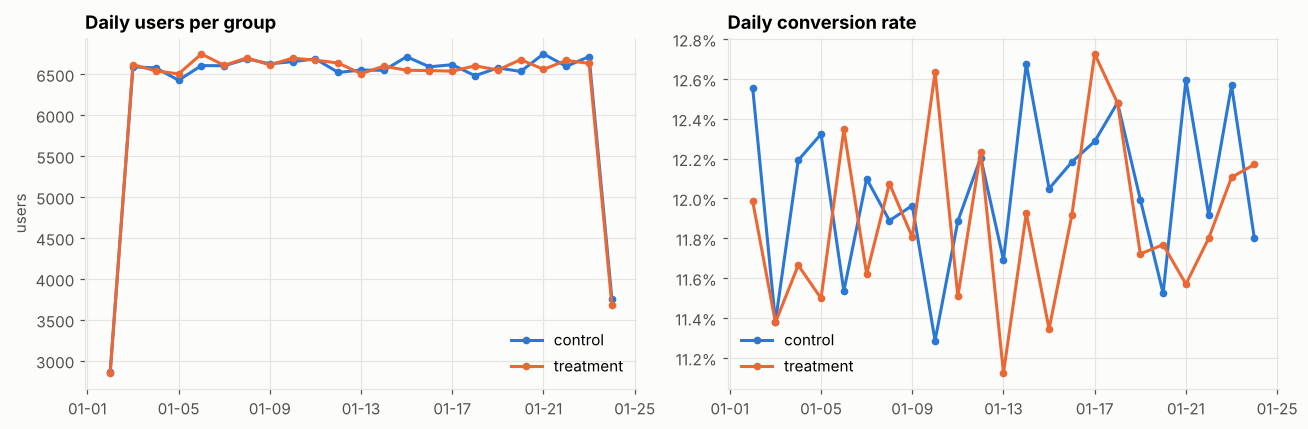

In [10]:
daily = (df.groupby(["date", "group"]).converted.agg(["count", "mean"]).reset_index())
daily["date"] = pd.to_datetime(daily["date"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for g, d in daily.groupby("group"):
    axes[0].plot(d.date, d["count"], color=GROUP_COLORS[g], label=g, marker="o", ms=4)
    axes[1].plot(d.date, d["mean"], color=GROUP_COLORS[g], label=g, marker="o", ms=4)
axes[0].set_title("Daily users per group")
axes[0].set_ylabel("users")
axes[1].set_title("Daily conversion rate")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
    ax.legend()
plt.tight_layout()
plt.savefig(FIG / "01_daily_traffic_conversion.png")
plt.show()

**解读**：
- 每日流量两组几乎重合（第一天和最后一天是不完整的日期，所以人数少），分流稳定。
- 每日转化率在 11%–13% 之间波动，两组交替领先，**没有看到新页面持续领先或持续落后的趋势**，也没有明显的新奇效应。
- 单日样本约 6,500 人/组，单日波动大是正常的，不要对单日差异过度解读。

## 6. 随机化是否成功：协变量平衡检查

随机分组的意义是让两组在**所有**特征上（无论观测到与否）分布相同，这样两组转化率的差异才能归因于页面。我们无法检查看不见的特征，但可以检查看得见的：国家。

使用**卡方独立性检验**：$H_0$：国家分布与分组无关。

In [11]:
ct = pd.crosstab(df.country, df.group)
display(ct.assign(control_share=ct.control / ct.control.sum(),
                  treatment_share=ct.treatment / ct.treatment.sum()))
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"chi2 = {chi2:.3f}, dof = {dof}, p = {p:.3f}")

group,control,treatment,control_share,treatment_share
country,,,,
CA,7198,7301,0.0495,0.0502
UK,36360,36106,0.2503,0.2485
US,101716,101903,0.7002,0.7013


chi2 = 1.789, dof = 2, p = 0.409


**解读**：p ≈ 0.4，国家分布在两组之间没有显著差异（美国约 70%、英国约 25%、加拿大约 5%），说明随机化有效。

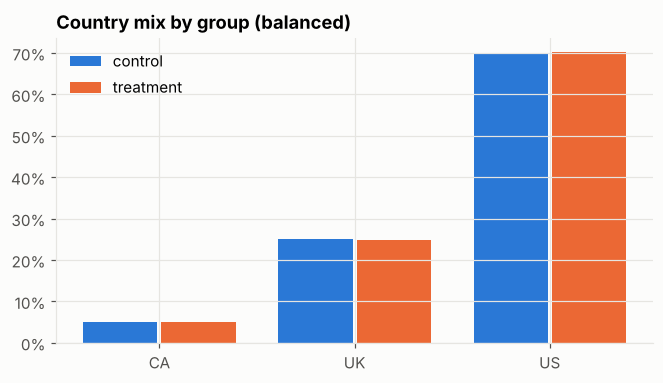

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
share = ct / ct.sum()
x = np.arange(len(share))
ax.bar(x - 0.2, share.control, 0.38, color=GROUP_COLORS["control"], label="control")
ax.bar(x + 0.2, share.treatment, 0.38, color=GROUP_COLORS["treatment"], label="treatment")
ax.set_xticks(x, share.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Country mix by group (balanced)")
ax.legend()
plt.savefig(FIG / "01_country_balance.png")
plt.show()

## 7. 本节小结

| 检查项 | 结果 | 处理 |
|---|---|---|
| 分组 / 页面错配 | 3,893 行，全部来自出现两次的用户，两组对称 | 删除错配行；敏感性分析显示结论不变 |
| 重复用户 | 1 个 | 保留首次曝光 |
| 缺失值 | 无 | — |
| SRM | p = 0.95，无失衡 | 通过 ✅ |
| 每日分流 | 稳定 | 通过 ✅ |
| 国家平衡 | p ≈ 0.4，平衡 | 通过 ✅ |

最终分析样本：**290,584 个用户**（对照组 145,274，实验组 145,310）。数据可信，进入下一步 → `02_core_hypothesis_testing.ipynb`。

### 🧠 自测题
1. 如果 SRM 检验 p = 0.0002，你会怎么做？（答：先**不看**效果结果，排查分流与埋点；找到原因前不得基于该实验做决策。）
2. 为什么不能用"每一行"而要用"每个用户"作为分析单位？（答：随机化单位是用户，同一用户的多次行为相关，按行计算会低估方差、夸大显著性。）